# Madrid rentals — Professor-aligned machine learning workflow

Code and technical outputs only. The supervised regression portion follows methods demonstrated in `Linear_Regression_Python (1).ipynb`: OLS, dummy encoding, median imputation, VIF, backward elimination, train/test prediction, residual plots and final reserved validation. **No HC3, log-rent, Cook’s distance, Breusch–Pagan or Jarque–Bera tests.** The final large-segment model is therefore a price-level OLS model and its metrics must be recalculated.

## 1. Imports and reproducible settings

In [2]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import statsmodels.api as sm
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans, DBSCAN
from sklearn.neighbors import NearestNeighbors
from sklearn.metrics import silhouette_score, r2_score, mean_absolute_error, mean_squared_error
from sklearn.model_selection import train_test_split
from sklearn.impute import SimpleImputer
from statsmodels.stats.outliers_influence import variance_inflation_factor

SEED = 42
DATA_PATH = Path(r"C:\Users\aopno\Downloads\Houses for rent in Madrid_2026 (2).xlsx")
OUTPUT_DIR = Path('madrid_ml_professor_outputs')
OUTPUT_DIR.mkdir(exist_ok=True)
assert DATA_PATH.exists(), f'Missing Excel workbook: {DATA_PATH}'


## 2. Load and audit original data

In [3]:
df = pd.read_excel(DATA_PATH, sheet_name='Houses_for_rent_madrid')
print('Shape:', df.shape)
print('Duplicate rows:', df.duplicated().sum(), 'Unique IDs:', df['Id'].nunique())
print('Missing values before cleaning:\n', df.isna().sum())
print(df.dtypes)
display(df.head())


Shape: (2070, 15)
Duplicate rows: 0 Unique IDs: 2070
Missing values before cleaning:
 Id                 0
District           0
Address            0
Number          1329
Area               4
Rent               0
Bedrooms          85
Sq.Mt              0
Floor            131
Outer            152
Elevator         124
Penthouse          0
Cottage            0
Duplex             0
Semidetached       0
dtype: int64
Id                int64
District         object
Address          object
Number           object
Area             object
Rent              int64
Bedrooms        float64
Sq.Mt             int64
Floor           float64
Outer           float64
Elevator        float64
Penthouse         int64
Cottage           int64
Duplex            int64
Semidetached      int64
dtype: object


,Id,District,Address,Number,Area,Rent,Bedrooms,Sq.Mt,Floor,Outer,Elevator,Penthouse,Cottage,Duplex,Semidetached
0,1,Ciudad Lineal,Piso en Quintana,NaN,Quintana,1346,2.0,72,3.0,1.0,1.0,0,0,0,0
1,2,Ciudad Lineal,Piso en calle de Arturo Soria,NaN,Costillares,3151,5.0,260,2.0,1.0,1.0,0,0,0,0
2,3,Ciudad Lineal,Piso en calle de Vicente Muzas,4,Colina,1375,2.0,100,3.0,1.0,1.0,0,0,0,0
3,4,Ciudad Lineal,Piso en calle Badajoz,NaN,San Pascual,1766,3.0,120,4.0,1.0,1.0,0,0,0,0
4,5,Ciudad Lineal,Piso en calle de Nuestra Señora del Villar,9,Ventas,907,2.0,60,3.0,1.0,0.0,0,0,0,0


## 3. Conservative cleaning

Studio descriptions support replacing their missing bedroom count with 0. Other missing bedroom counts are not invented. The anomalous floor 43039 is set to missing. Extreme rents/sizes and negative basement floors are retained. Original address is retained for checking but never entered as a numeric predictor.

In [4]:
clean = df.copy().replace('#NULL!', np.nan)
numeric_cols = ['Rent','Bedrooms','Sq.Mt','Floor','Outer','Elevator',
                'Penthouse','Cottage','Duplex','Semidetached']
clean[numeric_cols] = clean[numeric_cols].apply(pd.to_numeric, errors='coerce')
studio_mask = clean['Address'].str.startswith('Estudio', na=False) & clean['Bedrooms'].isna()
print('Studio bedroom values imputed to zero:', studio_mask.sum())
clean.loc[studio_mask, 'Bedrooms'] = 0
print('Floor errors corrected:', (clean['Floor'] == 43039).sum())
clean.loc[clean['Floor'] == 43039, 'Floor'] = np.nan
print('Missing after cleaning:\n', clean.isna().sum())
print('Remaining unknown bedrooms:\n', clean.loc[clean.Bedrooms.isna(), ['Id','Address','Sq.Mt']])
assert clean['Id'].is_unique


Studio bedroom values imputed to zero: 78
Floor errors corrected: 1
Missing after cleaning:
 Id                 0
District           0
Address            0
Number          1329
Area               4
Rent               0
Bedrooms           7
Sq.Mt              0
Floor            132
Outer            152
Elevator         124
Penthouse          0
Cottage            0
Duplex             0
Semidetached       0
dtype: int64
Remaining unknown bedrooms:
         Id                            Address  Sq.Mt
281    295     Dúplex en avenida de Manoteras     80
442    470      Ático en calle de la Princesa     35
1071  1131         Ático en calle de Valverde     45
1265  1338          Dúplex en Chueca-Justicia     47
1419  1500        Ático en avenida de Pío XII     67
1519  1603      Ático en calle Fuente del Saz     50
1755  1851  Ático en calle de Blasco de Garay     46


## 4. Exploratory diagnostics

,count,mean,std,min,25%,50%,75%,95%,max
Rent,2070.0,2046.364251,1497.715374,587.0,1073.25,1531.5,2578.5,4728.05,16100.0
Bedrooms,2063.0,2.396025,1.365262,0.0,1.00,2.0,3.0,5.00,8.0
Sq.Mt,2070.0,129.661836,116.005269,24.0,65.00,90.0,150.0,350.00,1250.0
Floor,1938.0,3.578431,3.006754,-1.0,2.00,3.0,5.0,9.00,29.0
Outer,1918.0,0.868092,0.338479,0.0,1.00,1.0,1.0,1.00,1.0
Elevator,1946.0,0.882323,0.322308,0.0,1.00,1.0,1.0,1.00,1.0
Penthouse,2070.0,0.081643,0.273885,0.0,0.00,0.0,0.0,1.00,1.0
Cottage,2070.0,0.042512,0.201803,0.0,0.00,0.0,0.0,0.00,1.0
Duplex,2070.0,0.030918,0.173137,0.0,0.00,0.0,0.0,0.00,1.0
Semidetached,2070.0,0.013527,0.115542,0.0,0.00,0.0,0.0,0.00,1.0


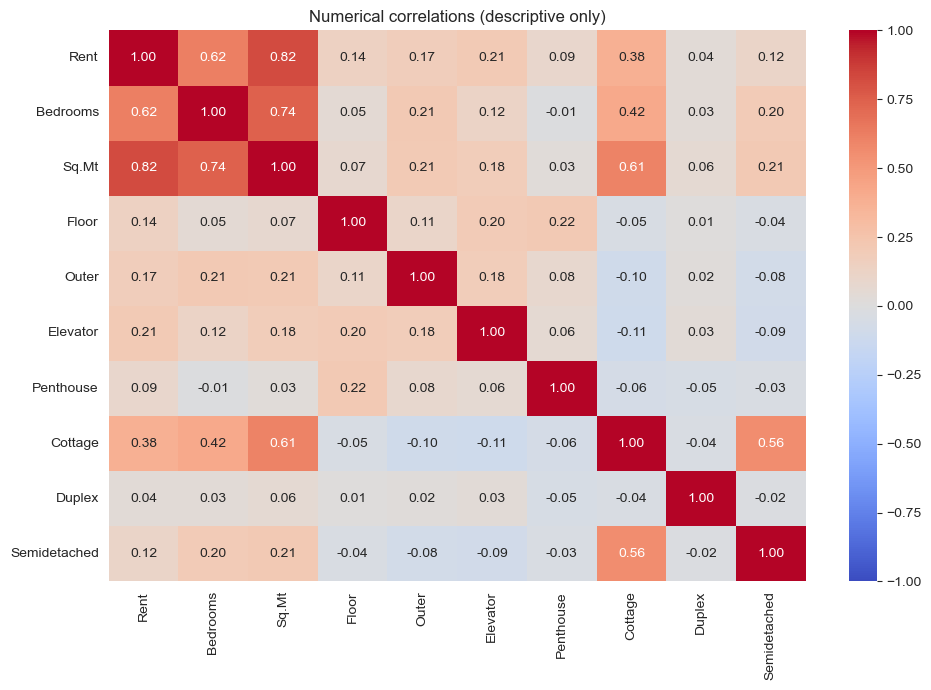

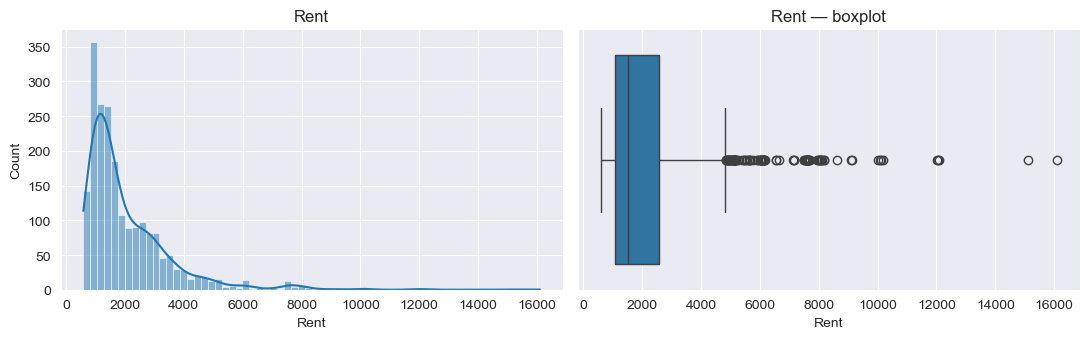

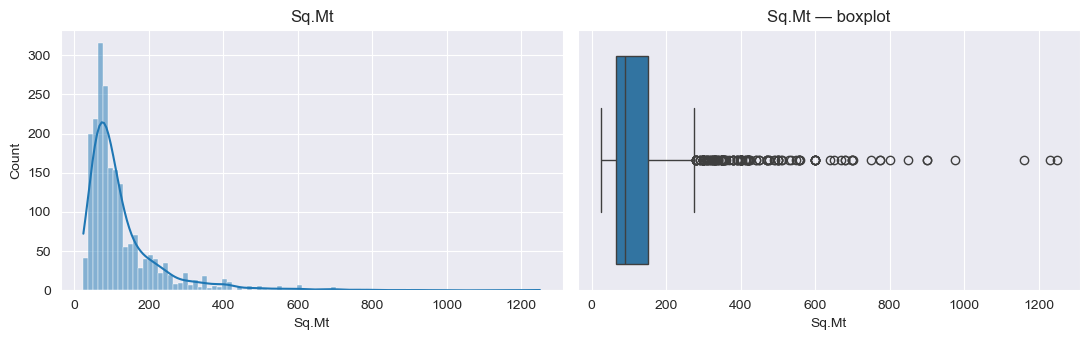

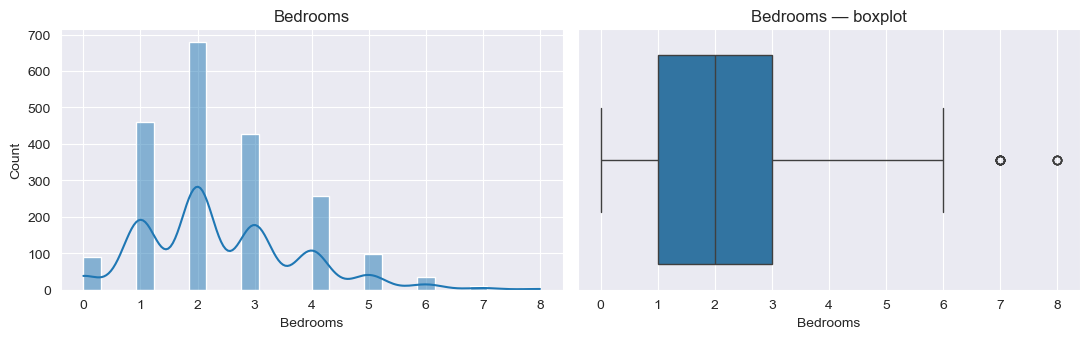

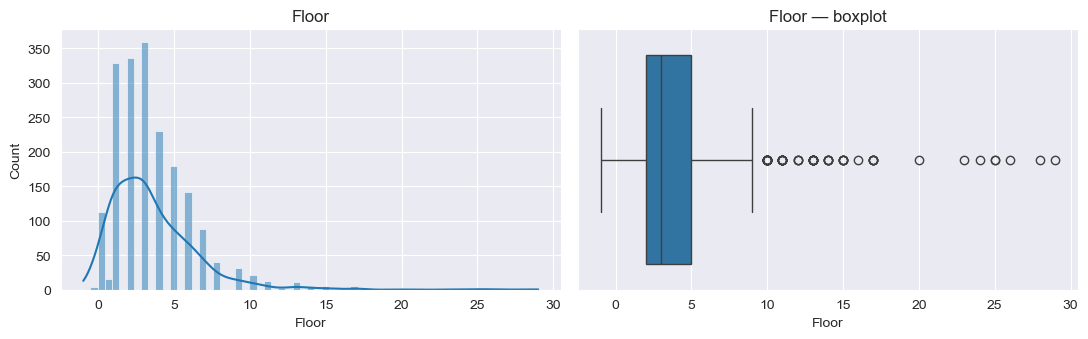

In [5]:
display(clean[numeric_cols].describe(percentiles=[.25,.5,.75,.95]).T)
plt.figure(figsize=(10,7))
sns.heatmap(clean[numeric_cols].corr(), annot=True, fmt='.2f', cmap='coolwarm', vmin=-1, vmax=1)
plt.title('Numerical correlations (descriptive only)')
plt.tight_layout(); plt.show()
for col in ['Rent','Sq.Mt','Bedrooms','Floor']:
    fig, axes = plt.subplots(1,2,figsize=(11,3.5))
    sns.histplot(x=clean[col].dropna(), kde=True, ax=axes[0], color="C0"); axes[0].set_title(col)
    sns.boxplot(x=clean[col], ax=axes[1]); axes[1].set_title(col+' — boxplot')
    plt.tight_layout(); plt.show()


,n,median_rent,median_area
District,,,
Salamanca,313,2607.0,120.0
Moncloa,160,2460.0,120.0
Chamartín,215,1866.0,107.0
Retiro,80,1801.0,119.0
Chamberí,194,1782.5,99.0
Hortaleza,117,1750.0,138.0
Centro,278,1586.0,71.5
Fuencarral,112,1431.5,110.0
Arganzuela,54,1353.0,90.0


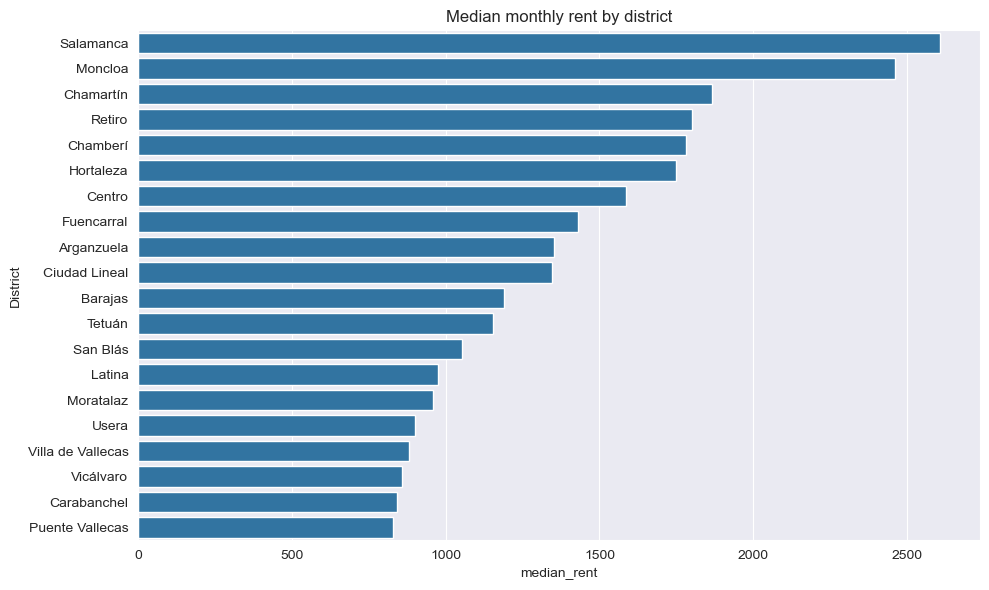

In [6]:
district_summary = clean.groupby('District').agg(n=('Id','count'),median_rent=('Rent','median'),median_area=('Sq.Mt','median')).sort_values('median_rent',ascending=False)
display(district_summary)
plt.figure(figsize=(10,6)); sns.barplot(data=district_summary.reset_index(),x='median_rent',y='District',color='C0')
plt.title('Median monthly rent by district'); plt.tight_layout(); plt.show()


## 5. Clustering feature configurations

Exclude `Rent` and `District` from distance-based clustering. We compare A (six predictors) and B (area, bedrooms, cottage). All scaling is fit on the clustering sample, since this is exploratory unsupervised segmentation. Missing-bedroom rows are excluded only from modeling, not from `clean`.

In [7]:
features_A = ['Sq.Mt','Bedrooms','Cottage','Penthouse','Duplex','Semidetached']
features_B = ['Sq.Mt','Bedrooms','Cottage']
cluster_df = clean.dropna(subset=features_A).copy()
scaled = {}
scalers = {}
for name, features in [('A',features_A),('B',features_B)]:
    scalers[name] = StandardScaler()
    scaled[name] = pd.DataFrame(scalers[name].fit_transform(cluster_df[features]),columns=features,index=cluster_df.index)
print('Usable listings:',len(cluster_df),'of',len(clean))
assert len(cluster_df)==2063


Usable listings: 2063 of 2070


## 6. Compare K-means solutions

Silhouette scores use up to 1,000 observations for speed; this approximation is used consistently across A and B. Replacing `sample_size=1000` with `None` calculates exact full-sample scores.

C:\Users\aopno\anaconda3\Lib\site-packages\joblib\externals\loky\backend\context.py:136: UserWarning: Could not find the number of physical cores for the following reason:
[WinError 2] El sistema no puede encontrar el archivo especificado
Returning the number of logical cores instead. You can silence this warning by setting LOKY_MAX_CPU_COUNT to the number of cores you want to use.
  warnings.warn(
  File "C:\Users\aopno\anaconda3\Lib\site-packages\joblib\externals\loky\backend\context.py", line 257, in _count_physical_cores
    cpu_info = subprocess.run(
        "wmic CPU Get NumberOfCores /Format:csv".split(),
        capture_output=True,
        text=True,
    )
  File "C:\Users\aopno\anaconda3\Lib\subprocess.py", line 554, in run
    with Popen(*popenargs, **kwargs) as process:
         ~~~~~^^^^^^^^^^^^^^^^^^^^^^
  File "C:\Users\aopno\anaconda3\Lib\subprocess.py", line 1039, in __init__
    self._execute_child(args, executable, preexec_fn, close_fds,
    ~~~~~~~~~~~~~~~~~~~^^^^^^

,Configuration,K,Inertia,Silhouette
0,A,2,8520.666809,0.741969
1,A,3,6433.018714,0.725722
2,A,4,4913.357783,0.557006
3,A,5,2883.033958,0.696137
4,A,6,1648.934549,0.568773
5,A,7,1251.535192,0.572421
6,A,8,1038.544815,0.568970
7,B,2,2972.160094,0.789449
8,B,3,1559.639108,0.538819
9,B,4,1096.952334,0.542707


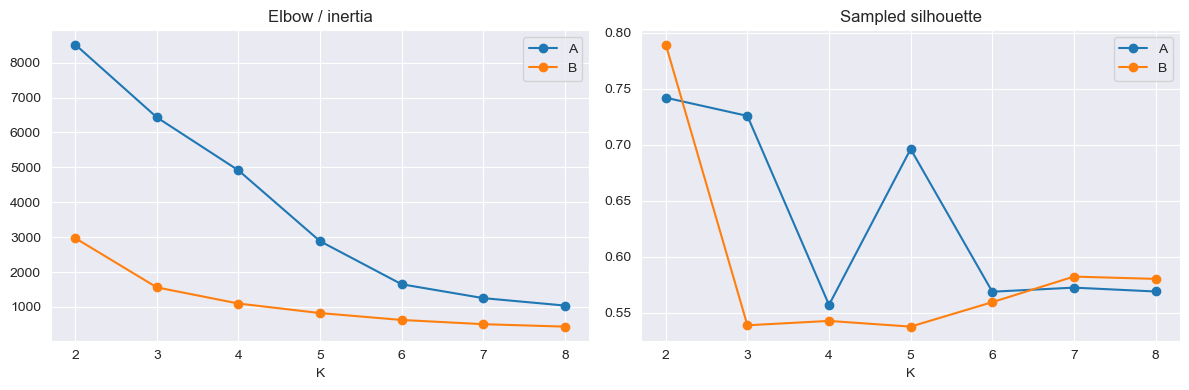

In [8]:
k_records=[]
for name, X in scaled.items():
    for k in range(2,9):
        model = KMeans(n_clusters=k,n_init=10,random_state=SEED)
        lab = model.fit_predict(X)
        score = silhouette_score(X,lab,sample_size=min(1000,len(X)),random_state=SEED)
        k_records.append({'Configuration':name,'K':k,'Inertia':model.inertia_,'Silhouette':score})
k_results = pd.DataFrame(k_records)
display(k_results)
fig,axes=plt.subplots(1,2,figsize=(12,4))
for name, part in k_results.groupby('Configuration'):
    axes[0].plot(part.K,part.Inertia,marker='o',label=name)
    axes[1].plot(part.K,part.Silhouette,marker='o',label=name)
axes[0].set_title('Elbow / inertia');axes[1].set_title('Sampled silhouette')
for ax in axes: ax.set_xlabel('K');ax.legend()
plt.tight_layout();plt.show()


## 7. Compare DBSCAN solutions

K-distance plot and epsilon sensitivity. DBSCAN assigns `-1` to noise; we report noise separately and do not treat it as an ordinary cluster for silhouette calculation.

,Configuration,eps,Clusters,Noise,Largest_cluster,Silhouette_without_noise
0,A,0.50,13,152,598,0.611678
1,A,0.75,5,89,1740,0.711042
2,A,1.00,5,17,1745,0.704297
3,A,1.25,5,10,1745,0.706727
4,A,1.50,5,3,1748,0.694692
5,A,2.00,5,3,1748,0.694692
6,B,0.35,8,95,680,0.603766
7,B,0.50,8,88,680,0.597479
8,B,0.75,3,28,1968,0.775182
9,B,1.00,2,10,1971,0.802102


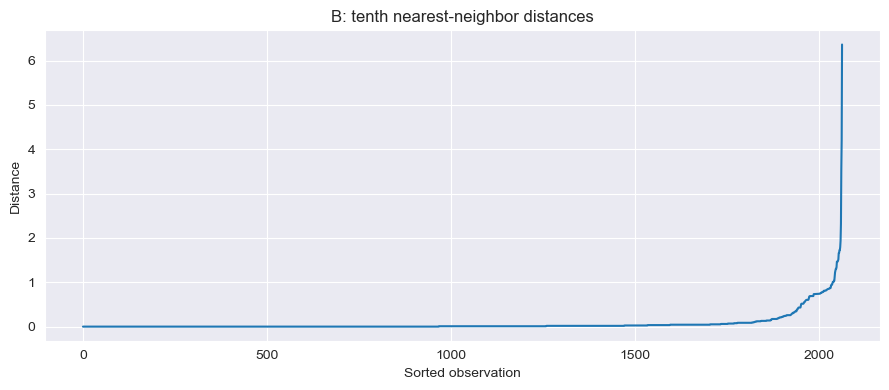

In [9]:
db_records=[]
for name,X in scaled.items():
    eps_values = [.5,.75,1.,1.25,1.5,2.] if name=='A' else [.35,.5,.75,1.]
    for eps in eps_values:
        labels=DBSCAN(eps=eps,min_samples=10).fit_predict(X)
        nonnoise=labels!=-1
        n_clusters=len(set(labels))-int(-1 in labels)
        sil=np.nan
        if n_clusters>=2 and len(set(labels[nonnoise]))>=2:
            sil=silhouette_score(X.loc[nonnoise], labels[nonnoise],sample_size=min(1000,nonnoise.sum()),random_state=SEED)
        db_records.append({'Configuration':name,'eps':eps,'Clusters':n_clusters,'Noise':(~nonnoise).sum(),'Largest_cluster':pd.Series(labels[nonnoise]).value_counts().max() if nonnoise.any() else 0,'Silhouette_without_noise':sil})
db_results=pd.DataFrame(db_records)
display(db_results)
neighbors=NearestNeighbors(n_neighbors=10).fit(scaled['B'])
distances,_=neighbors.kneighbors(scaled['B'])
plt.figure(figsize=(9,4));plt.plot(np.sort(distances[:,9]));plt.title('B: tenth nearest-neighbor distances');plt.xlabel('Sorted observation');plt.ylabel('Distance');plt.tight_layout();plt.show()


## 8. Candidate cluster profiling and selection

Use K-means B with K=4 as the previously chosen specification. Cluster IDs are algorithm labels, not ordered ranks. Profile rent only *after* clustering.

In [10]:
km = KMeans(n_clusters=4,n_init=10,random_state=SEED)
cluster_df['Cluster'] = km.fit_predict(scaled['B'])
db = DBSCAN(eps=.5,min_samples=10)
cluster_df['DBSCAN_Cluster'] = db.fit_predict(scaled['B'])

def profile(data, label):
    out=data.groupby(label).agg(n=('Id','count'),median_area=('Sq.Mt','median'),median_bedrooms=('Bedrooms','median'),median_rent=('Rent','median'),cottage_share=('Cottage','mean'))
    out['median_eur_per_sqm']=data.assign(eur_m2=data.Rent/data['Sq.Mt']).groupby(label).eur_m2.median()
    return out.round(2)
print('K-means');display(profile(cluster_df,'Cluster'))
print('DBSCAN');display(profile(cluster_df,'DBSCAN_Cluster'))
print('District % within K-means clusters:')
display((pd.crosstab(cluster_df.Cluster,cluster_df.District,normalize='index')*100).round(1))
cluster_df[['Id','Cluster','DBSCAN_Cluster']].to_csv(OUTPUT_DIR/'cluster_assignments.csv',index=False)


K-means


C:\Users\aopno\anaconda3\Lib\site-packages\sklearn\cluster\_kmeans.py:1419: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=9.
  warnings.warn(


,n,median_area,median_bedrooms,median_rent,cottage_share,median_eur_per_sqm
Cluster,,,,,,
0,1064,95.0,2.0,1485.0,0.00,15.42
1,89,412.0,5.0,4088.0,0.99,9.77
2,359,219.0,4.0,3105.0,0.00,14.30
3,551,55.0,1.0,1089.0,0.00,19.75


DBSCAN


,n,median_area,median_bedrooms,median_rent,cottage_share,median_eur_per_sqm
DBSCAN_Cluster,,,,,,
-1,88,365.0,5.0,4271.5,0.73,11.00
0,680,88.0,2.0,1431.5,0.00,16.49
1,73,250.0,5.0,3412.0,0.00,14.02
2,418,115.0,3.0,1606.0,0.00,14.21
3,461,60.0,1.0,1124.0,0.00,19.51
4,89,48.0,0.0,951.0,0.00,22.36
5,230,195.0,4.0,2745.0,0.00,14.56
6,11,400.0,4.0,3191.0,1.00,7.80
7,13,650.0,6.0,7512.0,1.00,10.73


District % within K-means clusters:


District,Arganzuela,Barajas,Carabanchel,Centro,Chamartín,Chamberí,Ciudad Lineal,Fuencarral,Hortaleza,Latina,Moncloa,Moratalaz,Puente Vallecas,Retiro,Salamanca,San Blás,Tetuán,Usera,Vicálvaro,Villa de Vallecas
Cluster,,,,,,,,,,,,,,,,,,,,
0,3.4,1.6,3.9,11.0,8.9,8.6,5.3,5.5,4.1,2.8,6.0,0.8,2.5,4.3,16.2,3.0,6.1,1.7,2.0,2.2
1,0.0,0.0,0.0,0.0,9.0,1.1,3.4,7.9,39.3,0.0,33.7,0.0,0.0,1.1,1.1,2.2,1.1,0.0,0.0,0.0
2,0.3,0.8,0.0,6.1,15.0,11.4,4.7,8.1,5.0,0.6,10.9,1.4,0.0,5.6,23.7,1.7,4.5,0.0,0.3,0.0
3,3.1,0.4,1.8,24.9,10.2,10.7,4.4,3.1,3.4,0.7,4.7,0.0,2.2,2.4,10.0,3.6,12.3,0.5,0.5,1.1


## 9. Freeze target segments and reserved samples

The selected clusters are 0 (medium) and 2 (large) for the fixed K-means run. Each segment has a 10% reserved sample, held out until the final model is selected. The remaining development set is split again into training and test.

In [11]:
target_segments=[0,2]
predictors=['Sq.Mt','Bedrooms','Floor','Outer','Elevator','Penthouse','Duplex','District']
segments={}
for cid in target_segments:
    seg=cluster_df.loc[cluster_df.Cluster==cid].copy()
    dev,res=train_test_split(seg,test_size=.10,random_state=SEED)
    tr,te=train_test_split(dev,test_size=.25,random_state=SEED)
    segments[cid]={'segment':seg,'dev':dev,'reserved':res,'train':tr,'test':te}
    print(f'Cluster {cid}: n={len(seg)} train={len(tr)} test={len(te)} reserve={len(res)}')


Cluster 0: n=1064 train=717 test=240 reserve=107
Cluster 2: n=359 train=242 test=81 reserve=36


## 10. Design matrix and conventional OLS

Dummy encoding, training-only median imputation, a reference district, a standard intercept, and backward elimination follow the professor’s regression notebook.

In [12]:
def dummy_features(frame):
    return pd.get_dummies(frame[predictors], columns=['District'], drop_first=False, dtype=int)

def training_design(train, test):
    a = dummy_features(train)
    b = dummy_features(test).reindex(columns=a.columns, fill_value=0)
    keep = a.columns[a.nunique(dropna=True) > 1].tolist()
    a = a[keep].copy()
    b = b[keep].copy()
    district_cols = sorted(c for c in keep if c.startswith('District_'))
    reference = district_cols[0] if district_cols else None
    if reference:
        a = a.drop(columns=reference)
        b = b.drop(columns=reference)
    imputer = SimpleImputer(strategy='median')
    a = pd.DataFrame(imputer.fit_transform(a), columns=a.columns, index=train.index)
    b = pd.DataFrame(imputer.transform(b), columns=b.columns, index=test.index)
    return a, b, reference

def ols_fit(X, y):
    return sm.OLS(y, sm.add_constant(X, has_constant='add')).fit()

def ols_predict(model, X):
    return np.asarray(model.predict(sm.add_constant(X, has_constant='add')))

def scores(y, p):
    return {'R2': r2_score(y, p), 'MAE': mean_absolute_error(y, p),
            'RMSE': np.sqrt(mean_squared_error(y, p))}

def backward_elimination(X, y, alpha=0.05):
    columns = X.columns.tolist()
    while len(columns) > 1:
        model = ols_fit(X[columns], y)
        p_values = model.pvalues.drop('const', errors='ignore')
        if p_values.empty or p_values.max() <= alpha:
            break
        columns.remove(p_values.idxmax())
    return columns


## 11. Full vs. reduced conventional OLS — training/test

Compare two ordinary rental-price OLS specifications per segment. The 10% reserved sample is not evaluated during model selection.

In [13]:
model_comparison = []
for cid, s in segments.items():
    A, B, reference = training_design(s['train'], s['test'])
    selected = backward_elimination(A, s['train'].Rent)
    s.update({'X_train': A, 'X_test': B, 'reference': reference,
              'reduced_columns': selected})
    for name, cols in [('Full OLS', A.columns.tolist()), ('Reduced OLS', selected)]:
        model = ols_fit(A[cols], s['train'].Rent)
        result = scores(s['test'].Rent, ols_predict(model, B[cols]))
        model_comparison.append({'Cluster': cid, 'Model': name, 'Terms': len(cols), **result})
    print(f'Cluster {cid}; omitted district dummy: {reference}')
    print('Reduced specification:', selected)
comparison = pd.DataFrame(model_comparison)
display(comparison.round(4))
comparison.to_csv(OUTPUT_DIR / 'development_model_comparison.csv', index=False)


Cluster 0; omitted district dummy: District_Arganzuela
Reduced specification: ['Sq.Mt', 'Bedrooms', 'Floor', 'Outer', 'District_Centro', 'District_Chamartín', 'District_Chamberí', 'District_Moncloa', 'District_Retiro', 'District_Salamanca', 'District_Tetuán']
Cluster 2; omitted district dummy: District_Barajas
Reduced specification: ['Sq.Mt', 'District_Centro', 'District_Chamartín', 'District_Retiro', 'District_Salamanca']


,Cluster,Model,Terms,R2,MAE,RMSE
0,0,Full OLS,26,0.6063,381.5495,572.3841
1,0,Reduced OLS,11,0.6047,384.2176,573.5624
2,2,Full OLS,20,0.7425,548.5298,782.7825
3,2,Reduced OLS,5,0.7237,557.6192,810.8704


## 12. VIF, conventional OLS summary and residual plots

The professor’s notebook demonstrates VIF, `statsmodels` OLS summaries, histograms of residuals, and actual-versus-predicted graphics. No additional hypothesis tests are introduced.

Cluster 0 full OLS summary:
                            OLS Regression Results                            
Dep. Variable:                   Rent   R-squared:                       0.579
Model:                            OLS   Adj. R-squared:                  0.563
Method:                 Least Squares   F-statistic:                     36.48
Date:                Sun, 18 Oct 2026   Prob (F-statistic):          2.79e-111
Time:                        20:12:52   Log-Likelihood:                -5587.2
No. Observations:                 717   AIC:                         1.123e+04
Df Residuals:                     690   BIC:                         1.135e+04
Df Model:                          26                                         
Covariance Type:            nonrobust                                         
                                 coef    std err          t      P>|t|      [0.025      0.975]
---------------------------------------------------------------------------------------

,Term,VIF
0,const,75.749921
21,District_Salamanca,5.693317
10,District_Centro,4.712571
12,District_Chamberí,4.254374
11,District_Chamartín,3.663563
23,District_Tetuán,3.395323
17,District_Moncloa,3.260364
13,District_Ciudad Lineal,3.047820
14,District_Fuencarral,2.973649
15,District_Hortaleza,2.688807


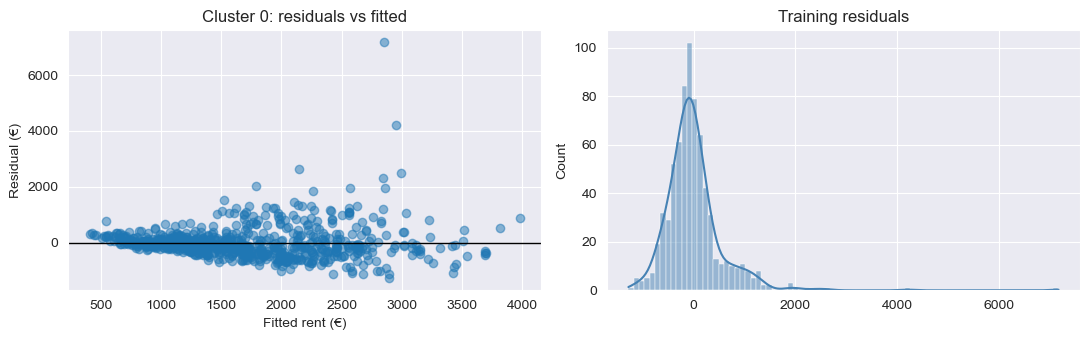

Cluster 2 full OLS summary:
                            OLS Regression Results                            
Dep. Variable:                   Rent   R-squared:                       0.620
Model:                            OLS   Adj. R-squared:                  0.585
Method:                 Least Squares   F-statistic:                     17.99
Date:                Sun, 18 Oct 2026   Prob (F-statistic):           6.02e-36
Time:                        20:12:52   Log-Likelihood:                -2048.3
No. Observations:                 242   AIC:                             4139.
Df Residuals:                     221   BIC:                             4212.
Df Model:                          20                                         
Covariance Type:            nonrobust                                         
                             coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------------------


,Term,VIF
0,const,261.727336
18,District_Salamanca,16.340819
9,District_Chamartín,11.941371
10,District_Chamberí,10.199769
15,District_Moncloa,9.312983
12,District_Fuencarral,6.460101
8,District_Centro,5.929037
20,District_Tetuán,5.236063
13,District_Hortaleza,5.063355
11,District_Ciudad Lineal,4.670044


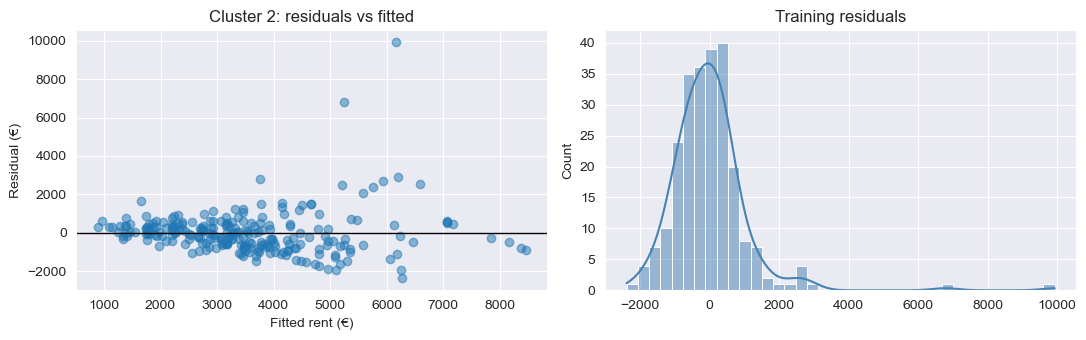

In [14]:
for cid, s in segments.items():
    X = s['X_train']
    y = s['train'].Rent
    model = ols_fit(X, y)
    exog = pd.DataFrame(sm.add_constant(X, has_constant='add'), index=X.index)
    vif = pd.DataFrame({
        'Term': exog.columns,
        'VIF': [variance_inflation_factor(exog.values.astype(float), i)
                for i in range(exog.shape[1])]
    })
    print('Cluster', cid, 'full OLS summary:')
    print(model.summary())
    display(vif.sort_values('VIF', ascending=False).head(12))
    fig, axes = plt.subplots(1, 2, figsize=(11, 3.5))
    axes[0].scatter(model.fittedvalues, model.resid, alpha=.5)
    axes[0].axhline(0, color='black', linewidth=1)
    axes[0].set_title(f'Cluster {cid}: residuals vs fitted')
    axes[0].set_xlabel('Fitted rent (€)')
    axes[0].set_ylabel('Residual (€)')
    sns.histplot(x=np.asarray(model.resid), kde=True, ax=axes[1], color='steelblue')
    axes[1].set_title('Training residuals')
    plt.tight_layout()
    plt.show()


## 13. Development prediction checks

Compare fitted versus observed rent on the training and test samples, as in the professor’s regression exercises.

0 Train {'R2': 0.5753479642584738, 'MAE': 371.4981539132326, 'RMSE': np.float64(588.6049820077229)}


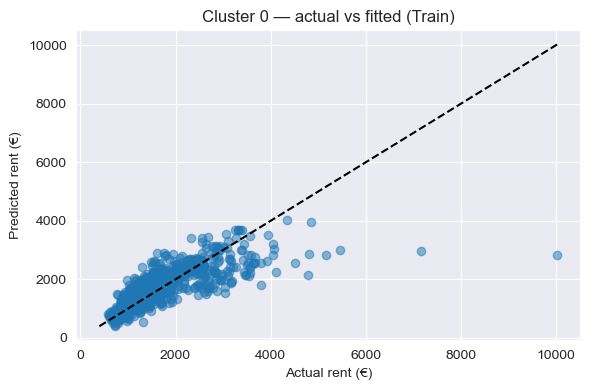

0 Test {'R2': 0.6046843182939492, 'MAE': 384.21755431198216, 'RMSE': np.float64(573.5624107972427)}


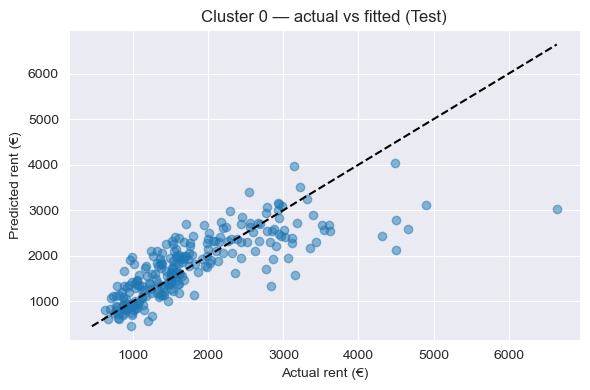

2 Train {'R2': 0.6195228677094329, 'MAE': 707.6907734245378, 'RMSE': np.float64(1147.3410331252637)}


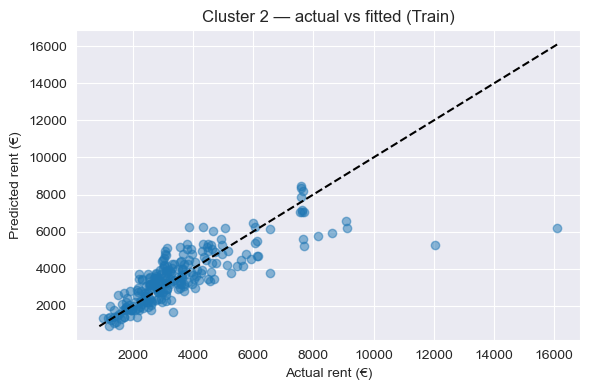

2 Test {'R2': 0.7425232839175475, 'MAE': 548.5297667019188, 'RMSE': np.float64(782.7824656534865)}


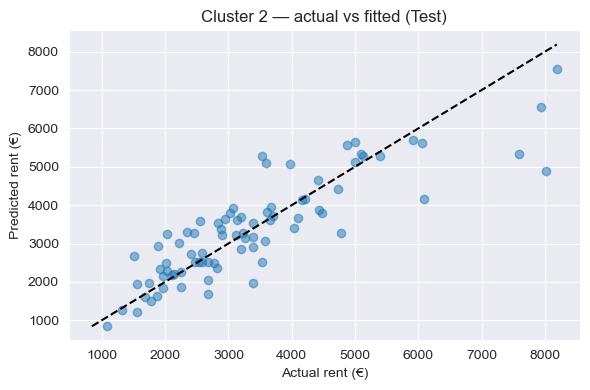

In [15]:
for cid, s in segments.items():
    cols = s['reduced_columns'] if cid == 0 else s['X_train'].columns.tolist()
    model = ols_fit(s['X_train'][cols], s['train'].Rent)
    for label, X_part, part in [('Train', s['X_train'], s['train']),
                                ('Test', s['X_test'], s['test'])]:
        pred = ols_predict(model, X_part[cols])
        print(cid, label, scores(part.Rent, pred))
        plt.figure(figsize=(6, 4))
        plt.scatter(part.Rent, pred, alpha=.5)
        lim = [min(part.Rent.min(), pred.min()), max(part.Rent.max(), pred.max())]
        plt.plot(lim, lim, 'k--')
        plt.title(f'Cluster {cid} — actual vs fitted ({label})')
        plt.xlabel('Actual rent (€)')
        plt.ylabel('Predicted rent (€)')
        plt.tight_layout()
        plt.show()


## 14. Final specifications (price-level OLS only)

Retain the earlier reduced specification for medium properties and compare it with the full price-level OLS for large properties. Log-rent is removed because it was not used in the professor’s regression notebook. The reserved sample is opened once in the following section.

In [16]:
frozen = {
    0: {'model': 'Reduced OLS', 'columns': segments[0]['reduced_columns']},
    2: {'model': 'Full OLS', 'columns': segments[2]['X_train'].columns.tolist()}
}
for cid, choice in frozen.items():
    print(cid, choice['model'], len(choice['columns']), 'predictors')


0 Reduced OLS 11 predictors
2 Full OLS 20 predictors


## 15. Refit on 90% development sample and evaluate once on the reserved 10%

Final models and imputers are fitted using development rows only. Outputs must be recalculated because the large-segment model no longer uses log rent.

In [17]:
reserved_summary = []
final_models = {}
for cid, s in segments.items():
    dev, reserved = s['dev'], s['reserved']
    selection = frozen[cid]
    cols = selection['columns']
    dev_raw = dummy_features(dev).reindex(columns=cols, fill_value=0)
    reserved_raw = dummy_features(reserved).reindex(columns=cols, fill_value=0)
    imputer = SimpleImputer(strategy='median')
    X_dev = pd.DataFrame(imputer.fit_transform(dev_raw), columns=cols, index=dev.index)
    X_reserved = pd.DataFrame(imputer.transform(reserved_raw), columns=cols, index=reserved.index)
    model = ols_fit(X_dev, dev.Rent)
    predictions = ols_predict(model, X_reserved)
    result = scores(reserved.Rent, predictions)
    reserved_summary.append({'Cluster': cid, 'Model': selection['model'],
                             'N_development': len(dev), 'N_reserved': len(reserved), **result})
    final_models[cid] = {'model': model, 'X_dev': X_dev,
                         'X_reserved': X_reserved, 'prediction': predictions,
                         'reference': s['reference']}
    pd.DataFrame({'Id': reserved.Id.to_numpy(), 'Actual_Rent': reserved.Rent.to_numpy(),
                  'Predicted_Rent': predictions,
                  'Residual': reserved.Rent.to_numpy() - predictions,
                  'Absolute_Error': abs(reserved.Rent.to_numpy() - predictions),
                  'District': reserved.District.to_numpy(),
                  'Sq.Mt': reserved['Sq.Mt'].to_numpy()}).to_csv(
        OUTPUT_DIR / f'cluster_{cid}_reserved_predictions.csv', index=False)
final_scores = pd.DataFrame(reserved_summary)
display(final_scores.round(3))
final_scores.to_csv(OUTPUT_DIR / 'final_reserved_scores.csv', index=False)


,Cluster,Model,N_development,N_reserved,R2,MAE,RMSE
0,0,Reduced OLS,957,107,0.580,379.952,517.491
1,2,Full OLS,323,36,0.818,579.525,713.034


## 16. Final conventional OLS regression tables

Use `model.summary()` and ordinary OLS coefficient/standard-error/p-value tables, consistent with the professor’s notebook. District effects are relative to the excluded reference district.

In [18]:
for cid, item in final_models.items():
    model = item['model']
    print(f'FINAL OLS — CLUSTER {cid}; reference: {item["reference"]}')
    print(model.summary())
    coefficients = pd.DataFrame({
        'Term': model.params.index,
        'Coefficient': model.params.values,
        'Std_Error': model.bse.values,
        't_statistic': model.tvalues.values,
        'p_value': model.pvalues.values,
        'CI_low': model.conf_int().iloc[:, 0].values,
        'CI_high': model.conf_int().iloc[:, 1].values
    })
    display(coefficients.round(4))
    coefficients.to_csv(OUTPUT_DIR / f'cluster_{cid}_OLS_coefficients.csv', index=False)
    preds = pd.read_csv(OUTPUT_DIR / f'cluster_{cid}_reserved_predictions.csv')
    display(preds.nlargest(5, 'Absolute_Error'))


FINAL OLS — CLUSTER 0; reference: District_Arganzuela
                            OLS Regression Results                            
Dep. Variable:                   Rent   R-squared:                       0.584
Model:                            OLS   Adj. R-squared:                  0.579
Method:                 Least Squares   F-statistic:                     120.7
Date:                Sun, 18 Oct 2026   Prob (F-statistic):          1.68e-171
Time:                        20:12:53   Log-Likelihood:                -7454.3
No. Observations:                 957   AIC:                         1.493e+04
Df Residuals:                     945   BIC:                         1.499e+04
Df Model:                          11                                         
Covariance Type:            nonrobust                                         
                         coef    std err          t      P>|t|      [0.025      0.975]
---------------------------------------------------------------------

,Term,Coefficient,Std_Error,t_statistic,p_value,CI_low,CI_high
0,const,-45.8195,115.3306,-0.3973,0.6912,-272.1533,180.5142
1,Sq.Mt,13.1543,0.6193,21.2395,0.0000,11.9389,14.3698
2,Bedrooms,-95.6046,41.0250,-2.3304,0.0200,-176.1152,-15.0940
3,Floor,28.3502,6.3131,4.4907,0.0000,15.9610,40.7395
4,Outer,176.3208,62.8968,2.8033,0.0052,52.8872,299.7544
5,District_Centro,742.7757,66.8192,11.1162,0.0000,611.6446,873.9067
6,District_Chamartín,417.8227,73.8176,5.6602,0.0000,272.9574,562.6880
7,District_Chamberí,644.6781,73.9422,8.7187,0.0000,499.5683,789.7880
8,District_Moncloa,469.0907,83.5644,5.6135,0.0000,305.0975,633.0839
9,District_Retiro,600.0224,105.6997,5.6767,0.0000,392.5892,807.4556


,Id,Actual_Rent,Predicted_Rent,Residual,Absolute_Error,District,Sq.Mt
9,852,1733,3835.823321,-2102.823321,2102.823321,Salamanca,200
67,715,959,2110.447218,-1151.447218,1151.447218,Salamanca,85
21,679,4663,3518.320296,1144.679704,1144.679704,Retiro,220
52,622,3849,2718.505939,1130.494061,1130.494061,Retiro,160
66,738,1237,2341.216487,-1104.216487,1104.216487,Salamanca,95


FINAL OLS — CLUSTER 2; reference: District_Barajas
                            OLS Regression Results                            
Dep. Variable:                   Rent   R-squared:                       0.646
Model:                            OLS   Adj. R-squared:                  0.622
Method:                 Least Squares   F-statistic:                     27.50
Date:                Sun, 18 Oct 2026   Prob (F-statistic):           2.93e-56
Time:                        20:12:53   Log-Likelihood:                -2709.5
No. Observations:                 323   AIC:                             5461.
Df Residuals:                     302   BIC:                             5540.
Df Model:                          20                                         
Covariance Type:            nonrobust                                         
                             coef    std err          t      P>|t|      [0.025      0.975]
--------------------------------------------------------------------

,Term,Coefficient,Std_Error,t_statistic,p_value,CI_low,CI_high
0,const,-976.2948,1049.6050,-0.9302,0.3530,-3041.7602,1089.1707
1,Sq.Mt,14.0480,0.8170,17.1947,0.0000,12.4402,15.6557
2,Bedrooms,-107.7944,90.1809,-1.1953,0.2329,-285.2570,69.6682
3,Floor,3.0473,25.6571,0.1188,0.9055,-47.4421,53.5366
4,Outer,794.9034,851.9395,0.9331,0.3515,-881.5859,2471.3927
5,Elevator,-63.6887,494.3133,-0.1288,0.8976,-1036.4232,909.0458
6,Penthouse,380.6325,218.2435,1.7441,0.0822,-48.8380,810.1030
7,Duplex,-132.0920,286.6070,-0.4609,0.6452,-696.0916,431.9075
8,District_Centro,1234.7332,575.9906,2.1437,0.0329,101.2699,2368.1964
9,District_Chamartín,1024.6814,522.4642,1.9612,0.0508,-3.4498,2052.8126


,Id,Actual_Rent,Predicted_Rent,Residual,Absolute_Error,District,Sq.Mt
24,1700,3686,5733.308949,-2047.308949,2047.308949,Chamberí,400
9,673,2317,3890.114955,-1573.114955,1573.114955,Retiro,220
20,757,5635,6762.884226,-1127.884226,1127.884226,Salamanca,440
17,1710,4562,5517.935178,-955.935178,955.935178,Chamberí,354
33,778,5570,6494.784494,-924.784494,924.784494,Salamanca,422


## 17. Reproducibility checks

Exports include cluster assignments, development model comparisons, conventional OLS coefficients, and reserved predictions. The report text remains the student’s own work.

In [19]:
print('Data rows:', len(df), 'Clustering rows:', len(cluster_df))
assert len(df) == 2070 and len(cluster_df) == 2063
assert set(frozen) == set(final_models)
assert final_scores['N_reserved'].sum() == 143
print('Outputs:')
for path in sorted(OUTPUT_DIR.glob('*.csv')):
    print(' -', path)


Data rows: 2070 Clustering rows: 2063
Outputs:
 - madrid_ml_professor_outputs\cluster_0_OLS_coefficients.csv
 - madrid_ml_professor_outputs\cluster_0_reserved_predictions.csv
 - madrid_ml_professor_outputs\cluster_2_OLS_coefficients.csv
 - madrid_ml_professor_outputs\cluster_2_reserved_predictions.csv
 - madrid_ml_professor_outputs\cluster_assignments.csv
 - madrid_ml_professor_outputs\development_model_comparison.csv
 - madrid_ml_professor_outputs\final_reserved_scores.csv
